# NuAncestor Multi-Orbit Visibility and Scheduling Analysis

This notebook automatically detects every `Results_aXXX_iYYY` folder in the selected base path and extracts the semi-major axis and inclination from each folder name.

For every orbit, it compares invalid nights & total contact time across the five visibility telescopes and evaluates how the number of invalid nights and valid nighttime contact change with the minimum valid-contact requirement. It also evaluates regional two- and three-telescope scheduling for Chile and Hawaii, including the sensitivity of three-telescope invalid nights to the contact requirement.

Finally, the notebook ranks every orbit on each plotted performance criterion and gives an overall ranking from the sum of the individual criterion ranks. Lower invalid-night counts and higher contact times rank better. There is both an unweighted and weighted ranking done.

Version 07/2026 by Pedro de S. C. Leonardo

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

from itertools import combinations, permutations
from matplotlib.ticker import MaxNLocator
from pathlib import Path
from IPython.display import display

In [2]:
# Main folder containing all Results_aXXX_iYYY simulation folders
BASE = Path("All_Results/PerfectingSMA")

# Settings to change !!
MULTIPLE_INCLINATIONS = False
DAYS = 365
CURRENT_CONTACT_REQUIREMENT_MIN = 30
VISIBILITY_CONTACT_REQUIREMENTS_MIN = [100, 90, 80, 70, 60, 50, 45, 40, 30, 28, 25, 22, 20, 18, 15]
SCHEDULING_CONTACT_REQUIREMENTS_MIN = [30, 28, 25, 22, 20, 18, 15]
MAX_CONSECUTIVE_MISSED_NIGHTS = 1  # Every-other-night requirement

# Conservative setting: regional telescope slots cannot overlap
ALLOW_SIMULTANEOUS_OBSERVATIONS = False
COMMON_NIGHT_MODE = "intersection"  # "intersection" or "union"
EXCLUDE_PARTIAL_EDGE_NIGHTS = True

# FreeFlyer output handling
TIME_MATCH_TOLERANCE_S = 1.0
GAP_FACTOR = 1.5  # A larger gap breaks a continuous interval

SAVE_FIGURES = False
SAVE_TABLES = False

# InContact.txt and IsNight.txt column order:
# time, Chile, LaPalma, Hawaii, SALT, DAG, HARPS, CORALIE,
# ESPRESSO, KPF, HIRES, MAROONX
VISIBILITY_TELESCOPES = ["Chile", "La Palma", "Hawaii", "SALT", "DAG"]
VISIBILITY_COLUMNS = {"Chile": 1, "La Palma": 2, "Hawaii": 3, "SALT": 4, "DAG": 5}
VISIBILITY_COLORS = {"Chile": "r", "La Palma": "blueviolet", "Hawaii": "cyan", "SALT": "orange", "DAG": "lime"}

REGIONAL_TELESCOPES = {
    "Chile": {"names": ["HARPS", "CORALIE", "ESPRESSO"], "columns": [6, 7, 8]},
    "Hawaii": {"names": ["KPF", "HIRES", "MAROONX"], "columns": [9, 10, 11]}}

RESULT_PATTERN = re.compile(r"^Results_a(?P<semi_major_axis>\d+)_i(?P<inclination>-?\d+)$")
detected_cases = []

for folder in BASE.iterdir():
    if not folder.is_dir():
        continue

    match = RESULT_PATTERN.fullmatch(folder.name)

    if match is None:
        continue

    semi_major_axis = int(match.group("semi_major_axis"))
    inclination = int(match.group("inclination"))
    detected_cases.append({
        "name": f"a = {semi_major_axis:,} km, i = {inclination}°",
        "semi_major_axis": semi_major_axis,
        "inclination": inclination,
        "folder": folder.name})

CASES = sorted(detected_cases, key=lambda case: (case["semi_major_axis"], case["inclination"]))

if not CASES:
    raise FileNotFoundError(f"No Results_aXXX_iYYY folders were found in {BASE}.")

detected_inclinations = sorted({case["inclination"] for case in CASES})
detected_multiple_inclinations = len(detected_inclinations) > 1

if MULTIPLE_INCLINATIONS != detected_multiple_inclinations:
    raise ValueError(
        f"MULTIPLE_INCLINATIONS is {MULTIPLE_INCLINATIONS}, but the detected inclinations are "
        f"{detected_inclinations}. Set MULTIPLE_INCLINATIONS to {detected_multiple_inclinations}.")

if CURRENT_CONTACT_REQUIREMENT_MIN not in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_CONTACT_REQUIREMENT_MIN must be included in VISIBILITY_CONTACT_REQUIREMENTS_MIN.")

if CURRENT_CONTACT_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_CONTACT_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

single_inclination = detected_inclinations[0] if not MULTIPLE_INCLINATIONS else None


def orbit_label(case):
    """Return the orbit label used in plot legends and on plot axes."""
    if MULTIPLE_INCLINATIONS:
        return f"a = {case['semi_major_axis']:,} km, i = {case['inclination']}°"

    return f"a = {case['semi_major_axis']:,} km"


def plot_title(title):
    """Add the inclination to plot titles only for a single-inclination analysis."""
    if MULTIPLE_INCLINATIONS:
        return title

    return f"{title}, i = {single_inclination}°"


def save_figure(fig, filename):
    """Save one analysis figure when requested."""
    if not SAVE_FIGURES:
        return

    output = BASE / "analysis_plots"
    output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output / filename, dpi=300, bbox_inches="tight")


print(f"Detected {len(CASES)} orbit folders with inclinations {detected_inclinations}.")
display(pd.DataFrame(CASES)[["semi_major_axis", "inclination", "folder"]].rename(columns={
    "semi_major_axis": "Semi-major axis [km]",
    "inclination": "Inclination [deg]",
    "folder": "Folder"}).style.hide(axis="index"))

Detected 16 orbit folders with inclinations [0].


Semi-major axis [km],Inclination [deg],Folder
21390,0,Results_a21390_i0
21480,0,Results_a21480_i0
21800,0,Results_a21800_i0
21850,0,Results_a21850_i0
21900,0,Results_a21900_i0
21930,0,Results_a21930_i0
22000,0,Results_a22000_i0
22300,0,Results_a22300_i0
22400,0,Results_a22400_i0
22500,0,Results_a22500_i0


In [3]:
# Main file loading and interval functions

ALL_STATION_COLUMNS = sorted(
    set(VISIBILITY_COLUMNS.values()) |
    {column for region in REGIONAL_TELESCOPES.values() for column in region["columns"]})


def read_result(folder, filename):
    """Read and clean one FreeFlyer results file."""
    path = BASE / folder / filename

    if not path.exists():
        raise FileNotFoundError(f"Result file not found: {path}")

    data = pd.read_csv(path, skiprows=3, sep=r"\s+", header=None, engine="python", dtype=str)

    # Remove repeated headers or other non-numeric lines
    data = data.apply(pd.to_numeric, errors="coerce").dropna(how="any")

    if data.empty:
        raise ValueError(f"No numeric data were found in {path}.")

    return data.sort_values(0).drop_duplicates(subset=0, keep="last").to_numpy(dtype=float)


def load_case_results(case):
    """Read, align and validate all contact and nighttime results for one orbit."""
    folder = case["folder"]
    contact_data = read_result(folder, "InContact.txt")
    night_data = read_result(folder, "IsNight.txt")
    required_column = max(ALL_STATION_COLUMNS)

    if contact_data.shape[1] <= required_column:
        raise ValueError(
            f"InContact.txt in {folder} must contain columns 0–{required_column}. "
            f"Found {contact_data.shape[1]} columns.")

    if night_data.shape[1] <= required_column:
        raise ValueError(
            f"IsNight.txt in {folder} must contain columns 0–{required_column}. "
            f"Found {night_data.shape[1]} columns.")

    contact = pd.DataFrame({"time": contact_data[:, 0], **{
        f"contact_{column}": contact_data[:, column] for column in ALL_STATION_COLUMNS}})
    night = pd.DataFrame({"time": night_data[:, 0], **{
        f"night_{column}": night_data[:, column] for column in ALL_STATION_COLUMNS}})

    contact = contact[(contact["time"] >= 0) & (contact["time"] < DAYS)]
    night = night[(night["time"] >= 0) & (night["time"] < DAYS)]

    merged = pd.merge_asof(
        contact.sort_values("time"), night.sort_values("time"),
        on="time", direction="nearest", tolerance=TIME_MATCH_TOLERANCE_S / 86400)

    night_columns = [f"night_{column}" for column in ALL_STATION_COLUMNS]
    unmatched = merged[night_columns].isna().any(axis=1)

    if unmatched.any():
        raise ValueError(
            f"{unmatched.sum()} contact rows in {folder} could not be matched to "
            "IsNight.txt within TIME_MATCH_TOLERANCE_S.")

    time = merged["time"].to_numpy()
    visible = merged[[f"contact_{column}" for column in ALL_STATION_COLUMNS]].to_numpy() >= 0.5
    is_night = merged[night_columns].to_numpy() >= 0.5

    if len(time) < 2:
        raise ValueError(f"At least two matched output samples are required in {folder}.")

    if not np.all(np.diff(time) > 0):
        raise ValueError(f"Output times remain non-increasing after cleaning in {folder}.")

    return time, visible, is_night


def infer_time_properties(time):
    """Infer nominal timing without requiring an exactly fixed step."""
    time_steps = np.diff(time)
    nominal_dt = np.median(time_steps)
    simulation_end = min(DAYS, time[-1] + nominal_dt)

    return {"nominal_dt": nominal_dt, "simulation_end": simulation_end}


def get_state_intervals(time, state, simulation_end, nominal_dt):
    """Return continuous True intervals using the actual timestamps."""
    state = np.asarray(state, dtype=bool)
    intervals = []
    start = None
    gap_limit = GAP_FACTOR * nominal_dt

    for i, active in enumerate(state):
        if active and start is None:
            start = time[i]

        if not active:
            continue

        is_last = i == len(state) - 1
        large_gap = not is_last and time[i + 1] - time[i] > gap_limit
        state_ends = not is_last and not state[i + 1]

        if is_last or large_gap or state_ends:
            if is_last:
                end = simulation_end
            elif large_gap:
                end = min(time[i] + nominal_dt, time[i + 1])
            else:
                end = time[i + 1]

            if end > start:
                intervals.append((start, end))

            start = None

    return intervals


def get_complete_nights(time, is_night, simulation_end, nominal_dt):
    """Return complete nighttime intervals."""
    nights = get_state_intervals(time, is_night, simulation_end, nominal_dt)

    if not EXCLUDE_PARTIAL_EDGE_NIGHTS or not nights:
        return nights

    if is_night[0]:
        nights = nights[1:]

    if is_night[-1] and nights:
        nights = nights[:-1]

    return nights


def clip_intervals(intervals, start, end):
    """Clip intervals to a single night."""
    clipped = []

    for interval_start, interval_end in intervals:
        clipped_start = max(interval_start, start)
        clipped_end = min(interval_end, end)

        if clipped_end > clipped_start:
            clipped.append((clipped_start, clipped_end))

    return clipped


def total_interval_hours(intervals):
    """Return the total duration of all intervals in hours."""
    return sum(end - start for start, end in intervals) * 24


def get_invalid_nights(feasible_nights):
    """Return nights violating the every-other-night requirement."""
    invalid_nights = np.zeros(len(feasible_nights), dtype=bool)
    missed_run = 0

    for i, feasible in enumerate(feasible_nights):
        missed_run = 0 if feasible else missed_run + 1
        invalid_nights[i] = missed_run > MAX_CONSECUTIVE_MISSED_NIGHTS

    return invalid_nights

In [4]:
# Visibility analysis functions

def evaluate_visibility_requirement(nights, contact_intervals, min_valid_contact_h):
    """Return invalid nights and valid nighttime contact for one telescope."""
    night_has_valid_contact = np.zeros(len(nights), dtype=bool)
    total_valid_contact_h = 0.0

    for night_index, (night_start, night_end) in enumerate(nights):
        nighttime_contacts = clip_intervals(contact_intervals, night_start, night_end)
        contact_durations_h = np.array([
            (contact_end - contact_start) * 24
            for contact_start, contact_end in nighttime_contacts])
        valid_contacts = contact_durations_h >= min_valid_contact_h - 1e-9

        night_has_valid_contact[night_index] = np.any(valid_contacts)
        total_valid_contact_h += contact_durations_h[valid_contacts].sum()

    invalid_nights = int(get_invalid_nights(night_has_valid_contact).sum())

    return invalid_nights, total_valid_contact_h

In [5]:
# Regional scheduling functions

def get_earliest_regional_slot(intervals, earliest_start, min_observation_h):
    """Return the earliest fixed-duration slot after a given time."""
    duration = min_observation_h / 24
    tolerance = 1e-12

    for start, end in intervals:
        slot_start = max(start, earliest_start)
        slot_end = slot_start + duration

        if slot_end <= end + tolerance:
            return slot_start, slot_end

    return None


def choose_regional_slots(station_intervals, required_telescopes, min_observation_h):
    """Choose the earliest feasible regional telescope combination."""
    telescope_indices = range(len(station_intervals))
    best = None

    for selected_indices in combinations(telescope_indices, required_telescopes):
        if ALLOW_SIMULTANEOUS_OBSERVATIONS:
            slots = {
                index: get_earliest_regional_slot(
                    station_intervals[index], -np.inf, min_observation_h)
                for index in selected_indices}

            if any(slot is None for slot in slots.values()):
                continue

            key = (
                max(slot[1] for slot in slots.values()),
                min(slot[0] for slot in slots.values()),
                selected_indices)

            if best is None or key < best[0]:
                best = (key, selected_indices, slots)

            continue

        for order in permutations(selected_indices):
            slots = {}
            previous_end = -np.inf

            for index in order:
                slot = get_earliest_regional_slot(
                    station_intervals[index], previous_end, min_observation_h)

                if slot is None:
                    break

                slots[index] = slot
                previous_end = slot[1]

            if len(slots) != required_telescopes:
                continue

            key = (
                previous_end,
                min(slot[0] for slot in slots.values()),
                order)

            if best is None or key < best[0]:
                best = (key, selected_indices, slots)

    return None if best is None else (best[1], best[2])


def evaluate_regional_scheduling(
    time, visible, is_night, simulation_end, nominal_dt, min_observation_h):
    """Return two- and three-telescope invalid nights for one region."""
    if COMMON_NIGHT_MODE == "intersection":
        common_night = np.all(is_night, axis=1)
    elif COMMON_NIGHT_MODE == "union":
        common_night = np.any(is_night, axis=1)
    else:
        raise ValueError("COMMON_NIGHT_MODE must be 'intersection' or 'union'.")

    nights = get_complete_nights(time, common_night, simulation_end, nominal_dt)

    if not nights:
        raise ValueError("No complete common nights were found.")

    station_intervals = [
        get_state_intervals(time, visible[:, i], simulation_end, nominal_dt)
        for i in range(3)]

    two_joint_feasible = []
    three_joint_feasible = []

    for night_start, night_end in nights:
        regional_intervals = [
            clip_intervals(intervals, night_start, night_end)
            for intervals in station_intervals]

        two_joint_feasible.append(
            choose_regional_slots(
                regional_intervals, 2, min_observation_h) is not None)
        three_joint_feasible.append(
            choose_regional_slots(
                regional_intervals, 3, min_observation_h) is not None)

    return {
        "Analysed nights": len(nights),
        "Two-telescope invalid nights": int(get_invalid_nights(two_joint_feasible).sum()),
        "Three-telescope invalid nights": int(get_invalid_nights(three_joint_feasible).sum())}

In [6]:
# Run the complete visibility and scheduling analysis

visibility_contact_rows = []
visibility_invalid_night_rows = []
visibility_sensitivity_rows = []
scheduling_sensitivity_rows = []

for case_index, case in enumerate(CASES, start=1):
    print(f"Analysing {case['name']} ({case_index}/{len(CASES)})...")

    time, visible, is_night = load_case_results(case)
    timing = infer_time_properties(time)
    simulation_end = timing["simulation_end"]
    nominal_dt = timing["nominal_dt"]

    visibility_totals = {
        requirement_min: {"invalid_nights": 0, "valid_contact_h": 0.0}
        for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN}

    for telescope in VISIBILITY_TELESCOPES:
        column_index = ALL_STATION_COLUMNS.index(VISIBILITY_COLUMNS[telescope])
        telescope_visible = visible[:, column_index]
        telescope_is_night = is_night[:, column_index]
        contact_intervals = get_state_intervals(
            time, telescope_visible, simulation_end, nominal_dt)
        nights = get_complete_nights(
            time, telescope_is_night, simulation_end, nominal_dt)

        if not nights:
            raise ValueError(
                f"No complete nighttime intervals were found for "
                f"{telescope} in {case['name']}.")

        visibility_contact_rows.append({
            "Orbit": case["name"],
            "Semi-major axis [km]": case["semi_major_axis"],
            "Inclination [deg]": case["inclination"],
            "Telescope": telescope,
            "Total contact [h]": total_interval_hours(contact_intervals)})

        for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
            invalid_nights, valid_contact_h = evaluate_visibility_requirement(
                nights, contact_intervals, requirement_min / 60)
            visibility_totals[requirement_min]["invalid_nights"] += invalid_nights
            visibility_totals[requirement_min]["valid_contact_h"] += valid_contact_h

            if requirement_min == CURRENT_CONTACT_REQUIREMENT_MIN:
                visibility_invalid_night_rows.append({
                    "Orbit": case["name"],
                    "Semi-major axis [km]": case["semi_major_axis"],
                    "Inclination [deg]": case["inclination"],
                    "Telescope": telescope,
                    "Invalid nights": invalid_nights})

    for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
        visibility_sensitivity_rows.append({
            "Orbit": case["name"],
            "Semi-major axis [km]": case["semi_major_axis"],
            "Inclination [deg]": case["inclination"],
            "Minimum valid contact [min]": requirement_min,
            "Total invalid nights": visibility_totals[requirement_min]["invalid_nights"],
            "Total valid contact [h]": visibility_totals[requirement_min]["valid_contact_h"]})

    for region_name, region in REGIONAL_TELESCOPES.items():
        region_indices = [ALL_STATION_COLUMNS.index(column) for column in region["columns"]]
        region_visible = visible[:, region_indices]
        region_is_night = is_night[:, region_indices]

        for requirement_min in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
            result = evaluate_regional_scheduling(
                time, region_visible, region_is_night,
                simulation_end, nominal_dt, requirement_min / 60)

            scheduling_sensitivity_rows.append({
                "Orbit": case["name"],
                "Semi-major axis [km]": case["semi_major_axis"],
                "Inclination [deg]": case["inclination"],
                "Region": region_name,
                "Minimum valid contact [min]": requirement_min,
                **result})

visibility_contact = pd.DataFrame(visibility_contact_rows)
visibility_invalid_nights = pd.DataFrame(visibility_invalid_night_rows)
visibility_sensitivity = pd.DataFrame(visibility_sensitivity_rows)
scheduling_sensitivity = pd.DataFrame(scheduling_sensitivity_rows)

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    visibility_contact.to_csv(output / "five_telescope_total_contact.csv", index=False)
    visibility_invalid_nights.to_csv(output / "five_telescope_invalid_nights_by_telescope.csv", index=False)
    visibility_sensitivity.to_csv(output / "five_telescope_requirement_sensitivity.csv", index=False)
    scheduling_sensitivity.to_csv(output / "regional_scheduling_requirement_sensitivity.csv", index=False)

print("Analysis complete.")

Analysing a = 21,390 km, i = 0° (1/16)...
Analysing a = 21,480 km, i = 0° (2/16)...
Analysing a = 21,800 km, i = 0° (3/16)...
Analysing a = 21,850 km, i = 0° (4/16)...
Analysing a = 21,900 km, i = 0° (5/16)...
Analysing a = 21,930 km, i = 0° (6/16)...
Analysing a = 22,000 km, i = 0° (7/16)...
Analysing a = 22,300 km, i = 0° (8/16)...
Analysing a = 22,400 km, i = 0° (9/16)...
Analysing a = 22,500 km, i = 0° (10/16)...
Analysing a = 22,600 km, i = 0° (11/16)...
Analysing a = 22,700 km, i = 0° (12/16)...
Analysing a = 22,800 km, i = 0° (13/16)...
Analysing a = 22,900 km, i = 0° (14/16)...
Analysing a = 23,000 km, i = 0° (15/16)...
Analysing a = 23,200 km, i = 0° (16/16)...
Analysis complete.


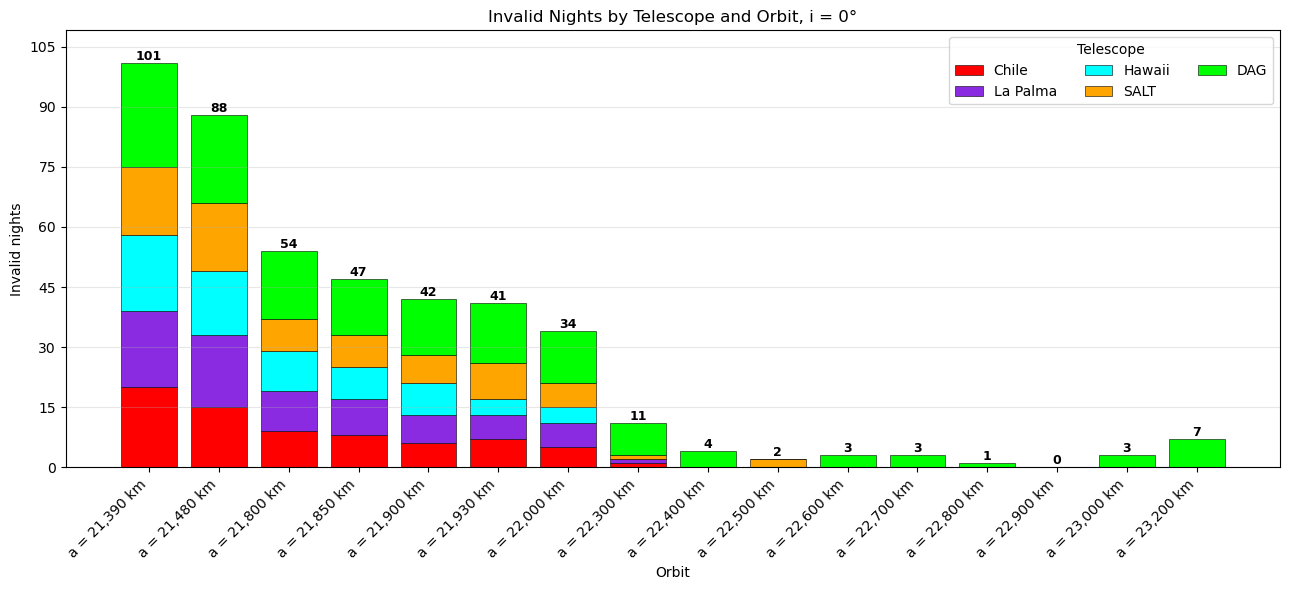

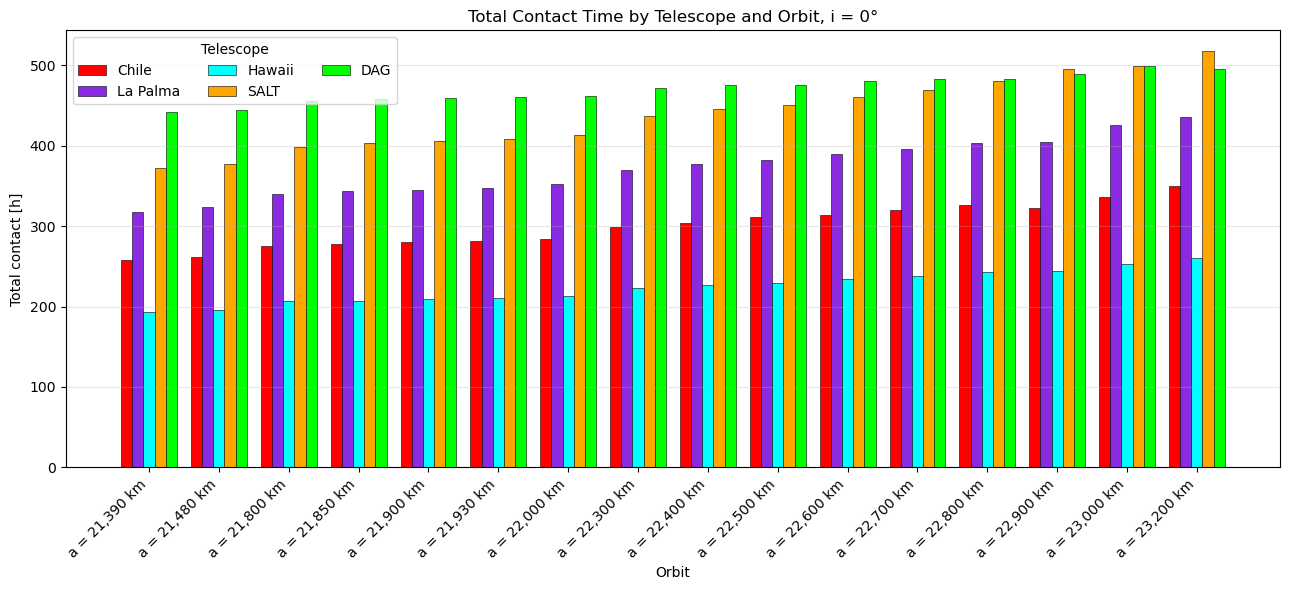

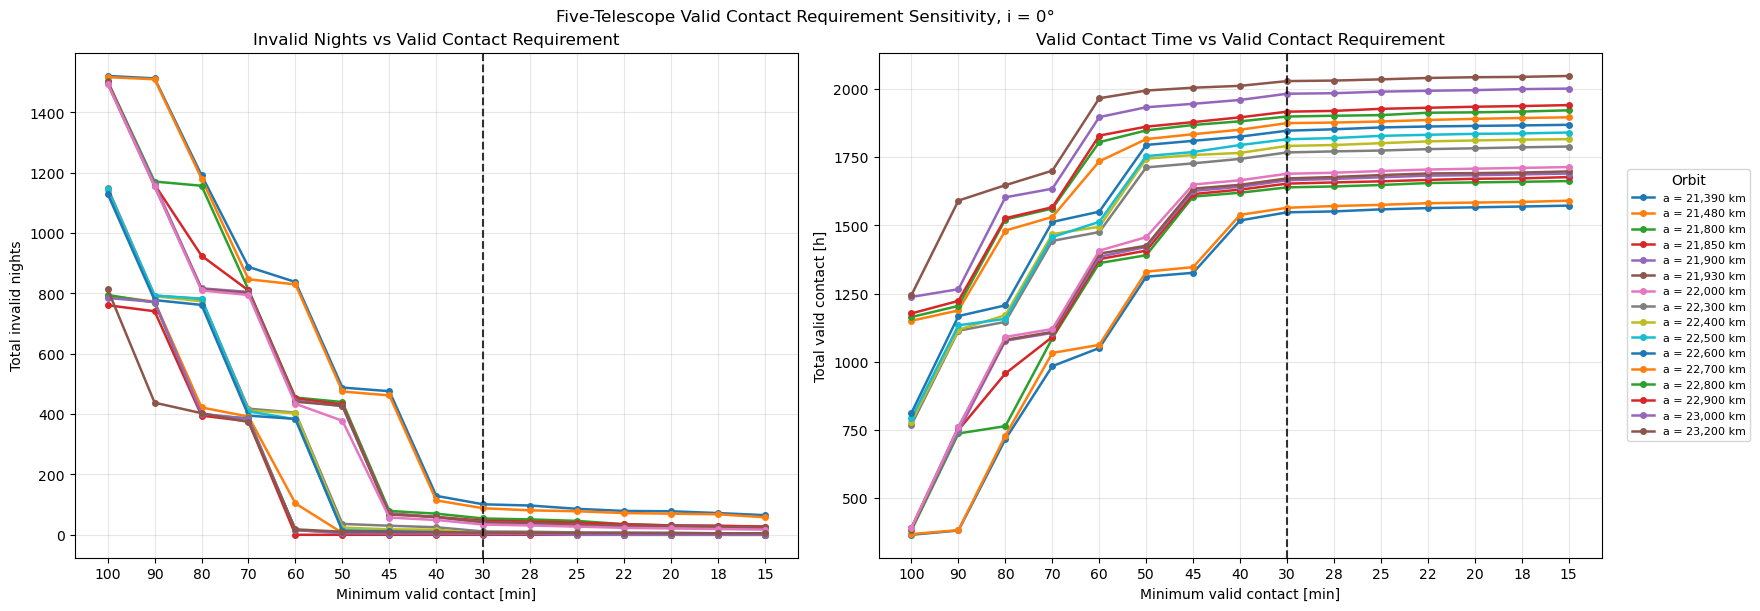

In [7]:
# Five-telescope visibility plots

orbit_order = [case["name"] for case in CASES]
orbit_labels = [orbit_label(case) for case in CASES]
x = np.arange(len(CASES))
bar_width = 0.8 / len(VISIBILITY_TELESCOPES)


# Five-telescope invalid nights

fig, ax = plt.subplots(figsize=(max(13, 0.8 * len(CASES)), 6))
invalid_night_totals = np.zeros(len(CASES))

for telescope in VISIBILITY_TELESCOPES:
    telescope_data = (
        visibility_invalid_nights[visibility_invalid_nights["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order))
    values = telescope_data["Invalid nights"].to_numpy()
    ax.bar(
        x, values, bottom=invalid_night_totals,
        color=VISIBILITY_COLORS[telescope], edgecolor="black",
        linewidth=0.4, label=telescope)
    invalid_night_totals += values

for position, total in zip(x, invalid_night_totals):
    ax.text(
        position, total, f"{int(total)}",
        ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title(plot_title("Invalid Nights by Telescope and Orbit"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Invalid nights")
ax.set_xticks(x)
ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
ax.margins(y=0.08)
fig.tight_layout()
save_figure(fig, "five_telescope_invalid_nights_by_orbit.png")
plt.show()


# Five-telescope total contact time


fig, ax = plt.subplots(figsize=(max(13, 0.8 * len(CASES)), 6))

for telescope_index, telescope in enumerate(VISIBILITY_TELESCOPES):
    telescope_data = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order))
    positions = x + (telescope_index - (len(VISIBILITY_TELESCOPES) - 1) / 2) * bar_width
    ax.bar(
        positions, telescope_data["Total contact [h]"],
        width=bar_width, color=VISIBILITY_COLORS[telescope],
        edgecolor="black", linewidth=0.4, label=telescope)

ax.set_title(plot_title("Total Contact Time by Telescope and Orbit"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Total contact [h]")
ax.set_xticks(x)
ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
fig.tight_layout()
save_figure(fig, "five_telescope_total_contact.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
x_requirement = np.arange(len(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

for case in CASES:
    orbit_data = (
        visibility_sensitivity[visibility_sensitivity["Orbit"] == case["name"]]
        .set_index("Minimum valid contact [min]")
        .reindex(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

    axes[0].plot(
        x_requirement, orbit_data["Total invalid nights"],
        marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))
    axes[1].plot(
        x_requirement, orbit_data["Total valid contact [h]"],
        marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))

axes[0].set_title("Invalid Nights vs Valid Contact Requirement")
axes[0].set_xlabel("Minimum valid contact [min]")
axes[0].set_ylabel("Total invalid nights")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

axes[1].set_title("Valid Contact Time vs Valid Contact Requirement")
axes[1].set_xlabel("Minimum valid contact [min]")
axes[1].set_ylabel("Total valid contact [h]")

for ax in axes:
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(VISIBILITY_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(
        VISIBILITY_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN),
        color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="Orbit",
    loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Five-Telescope Valid Contact Requirement Sensitivity"))
save_figure(fig, "five_telescope_valid_contact_requirement_sensitivity.png")
plt.show()

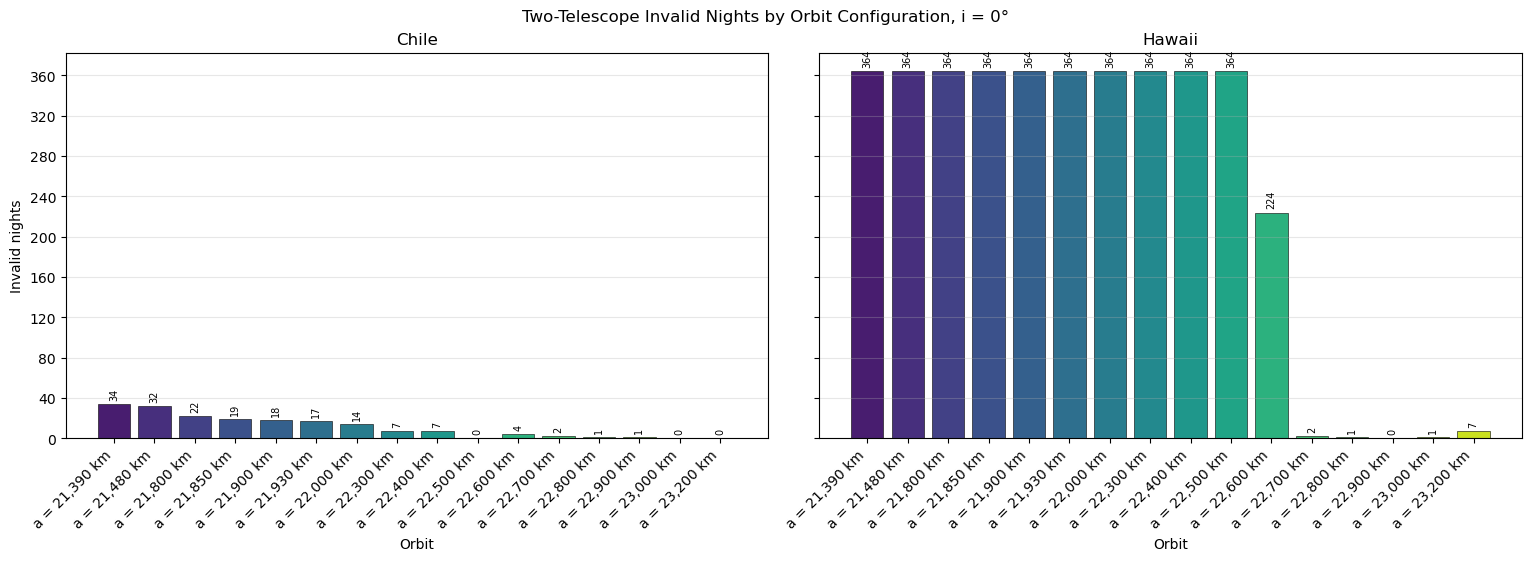

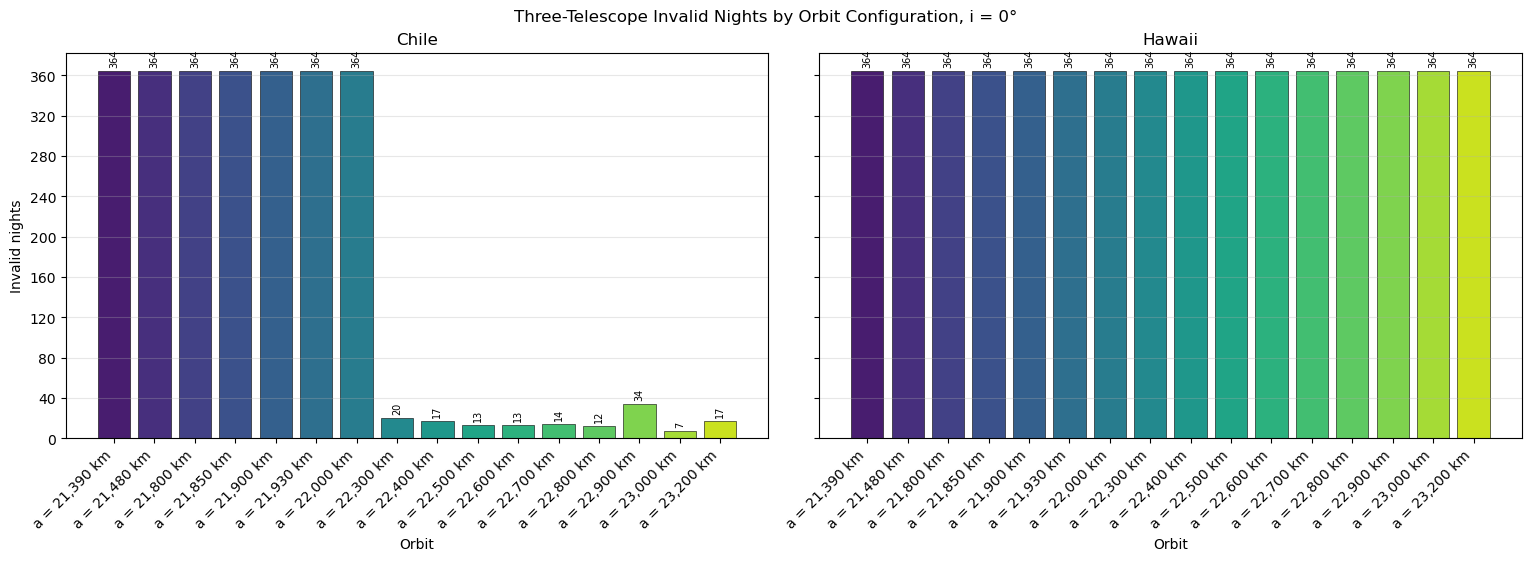

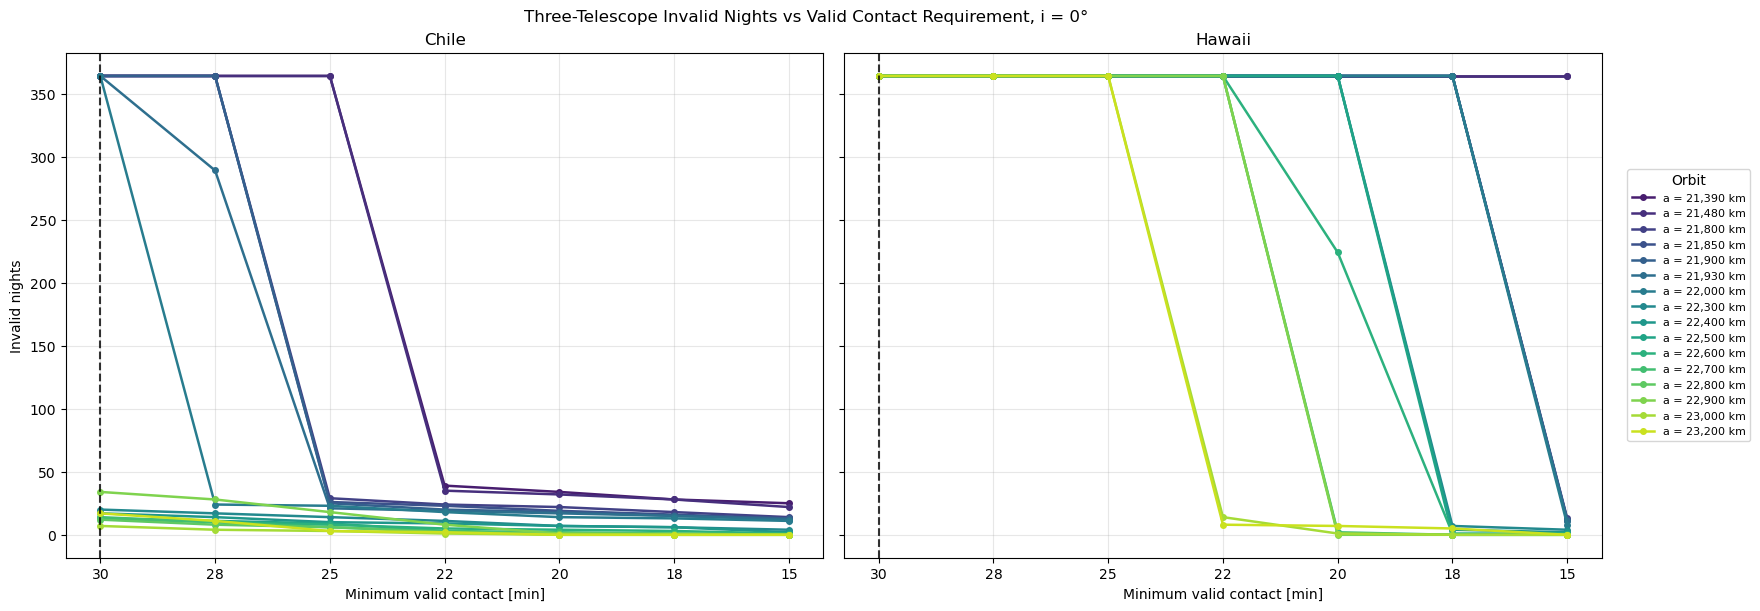

In [8]:
# Regional scheduling plots

current_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"]
    == CURRENT_CONTACT_REQUIREMENT_MIN]


def plot_regional_invalid_nights(value_column, title, filename):
    """Plot Chile and Hawaii invalid nights for all orbit cases."""
    fig, axes = plt.subplots(
        1, len(REGIONAL_TELESCOPES),
        figsize=(max(14, 0.95 * len(CASES)), 5.5),
        sharey=True, constrained_layout=True)

    if len(REGIONAL_TELESCOPES) == 1:
        axes = [axes]

    case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, len(CASES)))

    for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
        region_data = (
            current_scheduling[current_scheduling["Region"] == region_name]
            .set_index("Orbit").reindex(orbit_order))
        values = region_data[value_column].to_numpy()
        bars = ax.bar(x, values, color=case_colors, edgecolor="black", linewidth=0.4)
        ax.bar_label(bars, labels=[f"{int(value)}" for value in values], padding=3, fontsize=7, rotation=90)
        ax.set_title(region_name)
        ax.set_xlabel("Orbit")
        ax.set_xticks(x)
        ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel("Invalid nights")
    fig.suptitle(plot_title(title))
    save_figure(fig, filename)
    plt.show()


plot_regional_invalid_nights(
    "Two-telescope invalid nights",
    "Two-Telescope Invalid Nights by Orbit Configuration",
    "two_telescope_invalid_nights_by_orbit.png")

plot_regional_invalid_nights(
    "Three-telescope invalid nights",
    "Three-Telescope Invalid Nights by Orbit Configuration",
    "three_telescope_invalid_nights_by_orbit.png")

fig, axes = plt.subplots(
    1, len(REGIONAL_TELESCOPES),
    figsize=(16, 6), sharey=True, constrained_layout=True)

if len(REGIONAL_TELESCOPES) == 1:
    axes = [axes]

x_requirement = np.arange(len(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, len(CASES)))

for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
    region_data = scheduling_sensitivity[
        scheduling_sensitivity["Region"] == region_name]

    for case, color in zip(CASES, case_colors):
        orbit_data = (
            region_data[region_data["Orbit"] == case["name"]]
            .set_index("Minimum valid contact [min]")
            .reindex(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
        ax.plot(
            x_requirement, orbit_data["Three-telescope invalid nights"],
            marker="o", linewidth=1.8, markersize=4,
            color=color, label=orbit_label(case))

    ax.set_title(region_name)
    ax.set_xlabel("Minimum valid contact [min]")
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(SCHEDULING_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(
        SCHEDULING_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN),
        color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Invalid nights")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="Orbit",
    loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Three-Telescope Invalid Nights vs Valid Contact Requirement"))
save_figure(fig, "three_telescope_valid_contact_requirement_sensitivity.png")
plt.show()

## Orbit ranking:

Each orbit is ranked separately for every criterion: higher contact time and fewer invalid nights receive better ranks. The unweighted score sums all criterion ranks equally, while the weighted score multiplies each rank by an editable importance weight before summing. In both cases, the orbit with the lowest total score ranks highest.

The scheduling criteria use a 30-minute requirement per telescope for the two-telescope case and a 22-minute requirement per telescope for the three-telescope case (otherwise Hawaii 3-telescope scheduling gets no valid nights for any orbit).

**Caveat:** This is a relative rank-based comparison. It considers the ordering of the orbits, not the magnitude of their differences, so two nearly identical results can affect the score as much as two widely separated results. The selected weights are subjective and should therefore be tested for sensitivity.

### Unweighted orbit ranking:

Each orbit is ranked across 11 equally weighted performance criteria. Contact-time metrics are ranked in descending order, while invalid-night metrics are ranked in ascending order.

Ranks are assigned using `method="min"`, so tied orbits receive the same best applicable rank. The total ranking score is the sum of all individual criterion ranks, and the lowest total score determines overall rank 1. Tied values receive the same rank.

In [9]:
# Orbit ranking
# Every listed criterion has equal weight. Lower criterion and total scores are better.

# Change this if needed!!
# Scheduling requirements used in the ranking
CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN = 30
CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN = 22

if CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

if CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

ranking_values = pd.DataFrame(index=orbit_order)

for telescope in VISIBILITY_TELESCOPES:
    values = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order)["Total contact [h]"])
    ranking_values[f"{telescope} total contact [h]"] = values

current_visibility = (
    visibility_sensitivity[
        visibility_sensitivity["Minimum valid contact [min]"]
        == CURRENT_CONTACT_REQUIREMENT_MIN]
    .set_index("Orbit").reindex(orbit_order))

ranking_values["5-telescope invalid nights"] = (
    visibility_invalid_nights.groupby("Orbit")["Invalid nights"]
    .sum().reindex(orbit_order))
ranking_values["5-telescope valid contact [h]"] = current_visibility["Total valid contact [h]"]

current_two_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"]
    == CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN]

current_three_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"]
    == CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN]

for region_name in REGIONAL_TELESCOPES:
    two_telescope_data = (
        current_two_telescope_scheduling[
            current_two_telescope_scheduling["Region"] == region_name]
        .set_index("Orbit").reindex(orbit_order))

    three_telescope_data = (
        current_three_telescope_scheduling[
            current_three_telescope_scheduling["Region"] == region_name]
        .set_index("Orbit").reindex(orbit_order))

    ranking_values[f"{region_name} 2-telescope invalid nights"] = two_telescope_data["Two-telescope invalid nights"]
    ranking_values[f"{region_name} 3-telescope invalid nights"] = three_telescope_data["Three-telescope invalid nights"]

higher_is_better = {
    **{f"{telescope} total contact [h]": True for telescope in VISIBILITY_TELESCOPES},
    "5-telescope invalid nights": False,
    "5-telescope valid contact [h]": True,
    "Chile 2-telescope invalid nights": False,
    "Chile 3-telescope invalid nights": False,
    "Hawaii 2-telescope invalid nights": False,
    "Hawaii 3-telescope invalid nights": False}

criterion_ranks = pd.DataFrame(index=orbit_order)

for criterion, maximise in higher_is_better.items():
    criterion_ranks[f"{criterion} rank"] = ranking_values[criterion].rank(
        method="min", ascending=not maximise)

criterion_ranks["Total ranking score"] = criterion_ranks.sum(axis=1)
criterion_ranks["Overall rank"] = criterion_ranks["Total ranking score"].rank(
    method="min", ascending=True).astype(int)
criterion_ranks.index.name = "Orbit"

overall_ranking = criterion_ranks.sort_values(
    ["Overall rank", "Total ranking score"])

winner_rows = []

for criterion, maximise in higher_is_better.items():
    best_value = (
        ranking_values[criterion].max()
        if maximise else ranking_values[criterion].min())
    winners = ranking_values.index[
        np.isclose(ranking_values[criterion], best_value, rtol=0, atol=1e-9)]

    winner_rows.append({
        "Criterion": criterion,
        "Best orbit": " / ".join(winners),
        "Best value": best_value,
        "Preferred direction": "Higher" if maximise else "Lower"})

criterion_winners = pd.DataFrame(winner_rows)

print("Best orbit for each criterion:")
display(criterion_winners.round(2).style.hide(axis="index"))

print("\nOverall ranking:")
display(overall_ranking.round(2))

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    ranking_values.to_csv(output / "ranking_criterion_values.csv")
    criterion_ranks.to_csv(output / "ranking_criterion_ranks.csv")
    criterion_winners.to_csv(output / "ranking_criterion_winners.csv", index=False)
    overall_ranking.to_csv(output / "overall_orbit_ranking.csv")

Best orbit for each criterion:


Criterion,Best orbit,Best value,Preferred direction
Chile total contact [h],"a = 23,200 km, i = 0°",349.620000,Higher
La Palma total contact [h],"a = 23,200 km, i = 0°",435.300000,Higher
Hawaii total contact [h],"a = 23,200 km, i = 0°",260.860000,Higher
SALT total contact [h],"a = 23,200 km, i = 0°",517.640000,Higher
DAG total contact [h],"a = 23,000 km, i = 0°",499.170000,Higher
5-telescope invalid nights,"a = 22,900 km, i = 0°",0.000000,Lower
5-telescope valid contact [h],"a = 23,200 km, i = 0°",2029.320000,Higher
Chile 2-telescope invalid nights,"a = 22,500 km, i = 0° / a = 23,000 km, i = 0° / a = 23,200 km, i = 0°",0.000000,Lower
Chile 3-telescope invalid nights,"a = 23,000 km, i = 0°",1.000000,Lower
Hawaii 2-telescope invalid nights,"a = 22,900 km, i = 0°",0.000000,Lower



Overall ranking:


,Chile total contact [h] rank,La Palma total contact [h] rank,Hawaii total contact [h] rank,SALT total contact [h] rank,DAG total contact [h] rank,5-telescope invalid nights rank,5-telescope valid contact [h] rank,Chile 2-telescope invalid nights rank,Chile 3-telescope invalid nights rank,Hawaii 2-telescope invalid nights rank,Hawaii 3-telescope invalid nights rank,Total ranking score,Overall rank
Orbit,,,,,,,,,,,,,
"a = 23,000 km, i = 0°",2.0,2.0,2.0,2.0,1.0,4.0,2.0,1.0,1.0,2.0,2.0,21.0,1
"a = 23,200 km, i = 0°",1.0,1.0,1.0,1.0,2.0,8.0,1.0,1.0,2.0,5.0,1.0,24.0,2
"a = 22,900 km, i = 0°",4.0,3.0,3.0,3.0,3.0,1.0,3.0,4.0,7.0,1.0,3.0,35.0,3
"a = 22,800 km, i = 0°",3.0,4.0,4.0,4.0,4.0,2.0,4.0,4.0,2.0,2.0,3.0,36.0,4
"a = 22,700 km, i = 0°",5.0,5.0,5.0,5.0,5.0,4.0,5.0,6.0,4.0,4.0,3.0,51.0,5
"a = 22,500 km, i = 0°",7.0,7.0,7.0,7.0,7.0,3.0,7.0,1.0,4.0,7.0,3.0,60.0,6
"a = 22,600 km, i = 0°",6.0,6.0,6.0,6.0,6.0,4.0,6.0,7.0,6.0,6.0,3.0,62.0,7
"a = 22,400 km, i = 0°",8.0,8.0,8.0,8.0,8.0,7.0,8.0,8.0,8.0,7.0,3.0,81.0,8
"a = 22,300 km, i = 0°",9.0,9.0,9.0,9.0,9.0,9.0,9.0,8.0,9.0,7.0,3.0,90.0,9


### Weighted orbit ranking:

Each performance criterion is ranked in the same direction as in the unweighted ranking. The resulting rank is multiplied by its assigned weight, and the weighted ranks are summed. The orbit with the lowest total weighted score receives overall weighted rank 1.

Contact-time criteria initially have low and equal weights. Five-telescope invalid nights have the highest weight, followed by two-telescope and then three-telescope scheduling invalid nights. Telescope and regional multipliers can be adjusted independently.

In [10]:
# Weighted orbit ranking
# Criterion ranks are multiplied by editable weights. Lower weighted and total scores are better.

# Settings to change !!
CONTACT_TIME_WEIGHT = 1.0
TELESCOPE_WEIGHTS = {telescope: 1.0 for telescope in VISIBILITY_TELESCOPES}
# eg. to make Hawaii twice as important as others, set TELESCOPE_WEIGHTS = {"Chile": 1.0, "La Palma": 1.0, "Hawaii": 2.0, "SALT": 1.0, "DAG": 1.0}
FIVE_TELESCOPE_VALID_CONTACT_WEIGHT = 1.0
FIVE_TELESCOPE_INVALID_NIGHTS_WEIGHT = 5.0
TWO_TELESCOPE_INVALID_NIGHTS_WEIGHT = 4.0
THREE_TELESCOPE_INVALID_NIGHTS_WEIGHT = 3.0
REGION_WEIGHTS = {region_name: 1.0 for region_name in REGIONAL_TELESCOPES}

criterion_weights = {
    **{f"{telescope} total contact [h]": CONTACT_TIME_WEIGHT * TELESCOPE_WEIGHTS[telescope] for telescope in VISIBILITY_TELESCOPES},
    "5-telescope invalid nights": FIVE_TELESCOPE_INVALID_NIGHTS_WEIGHT,
    "5-telescope valid contact [h]": FIVE_TELESCOPE_VALID_CONTACT_WEIGHT,
    **{f"{region_name} 2-telescope invalid nights": TWO_TELESCOPE_INVALID_NIGHTS_WEIGHT * REGION_WEIGHTS[region_name] for region_name in REGIONAL_TELESCOPES},
    **{f"{region_name} 3-telescope invalid nights": THREE_TELESCOPE_INVALID_NIGHTS_WEIGHT * REGION_WEIGHTS[region_name] for region_name in REGIONAL_TELESCOPES}}

if set(criterion_weights) != set(higher_is_better):
    raise ValueError("criterion_weights must contain exactly the same criteria as higher_is_better.")

weighted_criterion_ranks = pd.DataFrame(index=orbit_order)

for criterion, maximise in higher_is_better.items():
    criterion_rank = ranking_values[criterion].rank(
        method="min", ascending=not maximise)
    weighted_criterion_ranks[f"{criterion} weighted rank"] = criterion_rank * criterion_weights[criterion]

weighted_criterion_ranks["Total weighted score"] = weighted_criterion_ranks.sum(axis=1)
weighted_criterion_ranks["Overall weighted rank"] = weighted_criterion_ranks["Total weighted score"].rank(
    method="min", ascending=True).astype(int)
weighted_criterion_ranks.index.name = "Orbit"

weighted_overall_ranking = weighted_criterion_ranks.sort_values(
    ["Overall weighted rank", "Total weighted score"])

weight_table = pd.DataFrame({
    "Criterion": list(higher_is_better),
    "Weight": [criterion_weights[criterion] for criterion in higher_is_better]})

print("Weighted ranking criteria:")
display(weight_table.round(2).style.hide(axis="index"))

print("\nWeighted overall ranking:")
display(weighted_overall_ranking.round(2))

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    weight_table.to_csv(output / "weighted_ranking_criterion_weights.csv", index=False)
    weighted_criterion_ranks.to_csv(output / "weighted_ranking_criterion_scores.csv")
    weighted_overall_ranking.to_csv(output / "weighted_overall_orbit_ranking.csv")

Weighted ranking criteria:


Criterion,Weight
Chile total contact [h],1.000000
La Palma total contact [h],1.000000
Hawaii total contact [h],1.000000
SALT total contact [h],1.000000
DAG total contact [h],1.000000
5-telescope invalid nights,5.000000
5-telescope valid contact [h],1.000000
Chile 2-telescope invalid nights,4.000000
Chile 3-telescope invalid nights,3.000000
Hawaii 2-telescope invalid nights,4.000000



Weighted overall ranking:


,Chile total contact [h] weighted rank,La Palma total contact [h] weighted rank,Hawaii total contact [h] weighted rank,SALT total contact [h] weighted rank,DAG total contact [h] weighted rank,5-telescope invalid nights weighted rank,5-telescope valid contact [h] weighted rank,Chile 2-telescope invalid nights weighted rank,Chile 3-telescope invalid nights weighted rank,Hawaii 2-telescope invalid nights weighted rank,Hawaii 3-telescope invalid nights weighted rank,Total weighted score,Overall weighted rank
Orbit,,,,,,,,,,,,,
"a = 23,000 km, i = 0°",2.0,2.0,2.0,2.0,1.0,20.0,2.0,4.0,3.0,8.0,6.0,52.0,1
"a = 22,800 km, i = 0°",3.0,4.0,4.0,4.0,4.0,10.0,4.0,16.0,6.0,8.0,9.0,72.0,2
"a = 22,900 km, i = 0°",4.0,3.0,3.0,3.0,3.0,5.0,3.0,16.0,21.0,4.0,9.0,74.0,3
"a = 23,200 km, i = 0°",1.0,1.0,1.0,1.0,2.0,40.0,1.0,4.0,6.0,20.0,3.0,80.0,4
"a = 22,500 km, i = 0°",7.0,7.0,7.0,7.0,7.0,15.0,7.0,4.0,12.0,28.0,9.0,110.0,5
"a = 22,700 km, i = 0°",5.0,5.0,5.0,5.0,5.0,20.0,5.0,24.0,12.0,16.0,9.0,111.0,6
"a = 22,600 km, i = 0°",6.0,6.0,6.0,6.0,6.0,20.0,6.0,28.0,18.0,24.0,9.0,135.0,7
"a = 22,400 km, i = 0°",8.0,8.0,8.0,8.0,8.0,35.0,8.0,32.0,24.0,28.0,9.0,176.0,8
"a = 22,300 km, i = 0°",9.0,9.0,9.0,9.0,9.0,45.0,9.0,32.0,27.0,28.0,9.0,195.0,9


Top four weighted-ranked orbits:


,Total weighted score,Overall weighted rank
Orbit,,
"a = 23,000 km, i = 0°",52.0,1
"a = 22,800 km, i = 0°",72.0,2
"a = 22,900 km, i = 0°",74.0,3
"a = 23,200 km, i = 0°",80.0,4


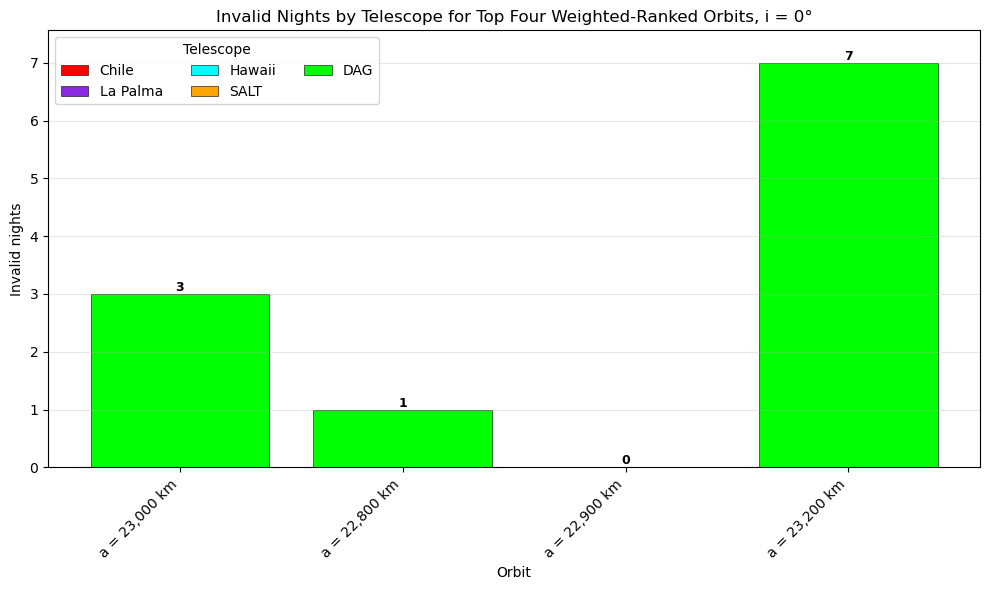

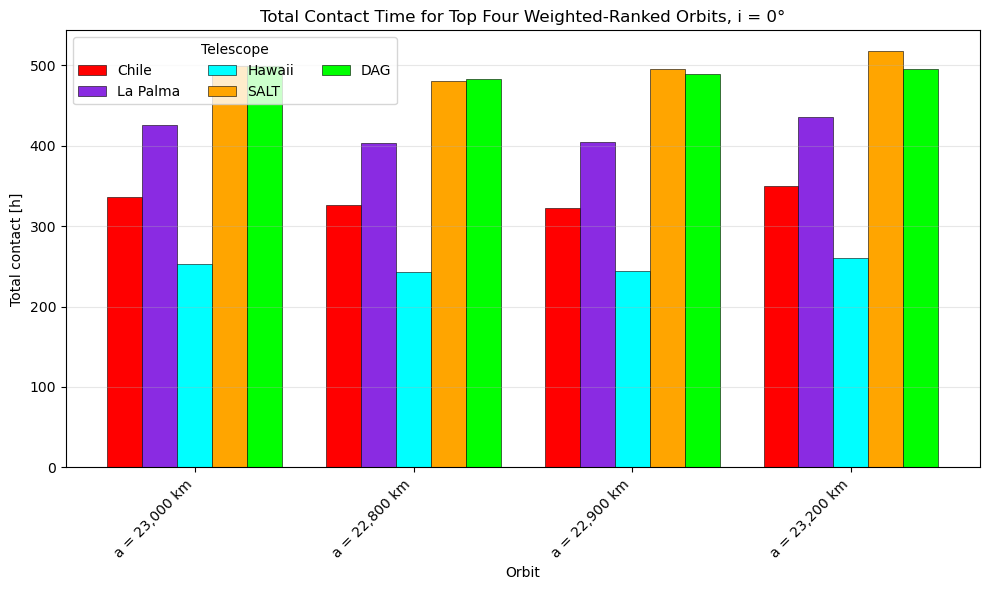

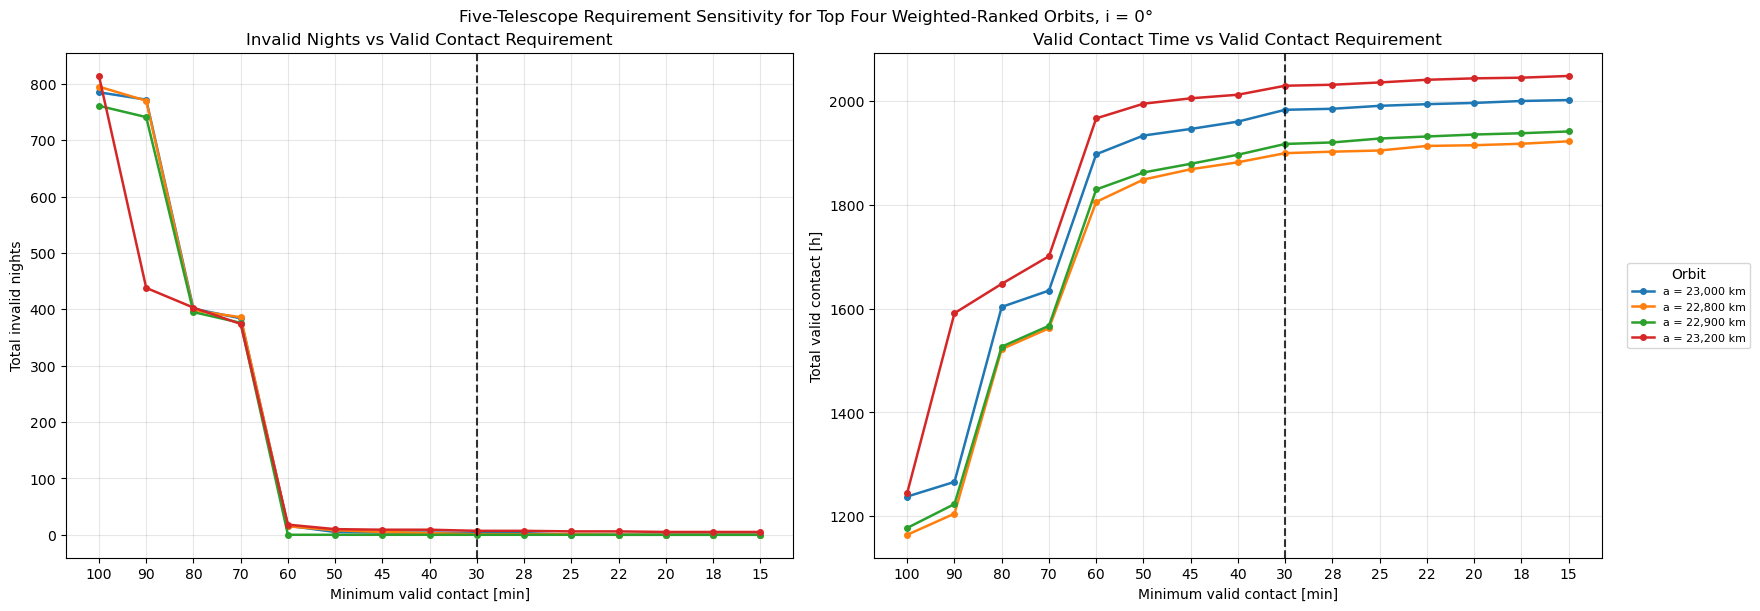

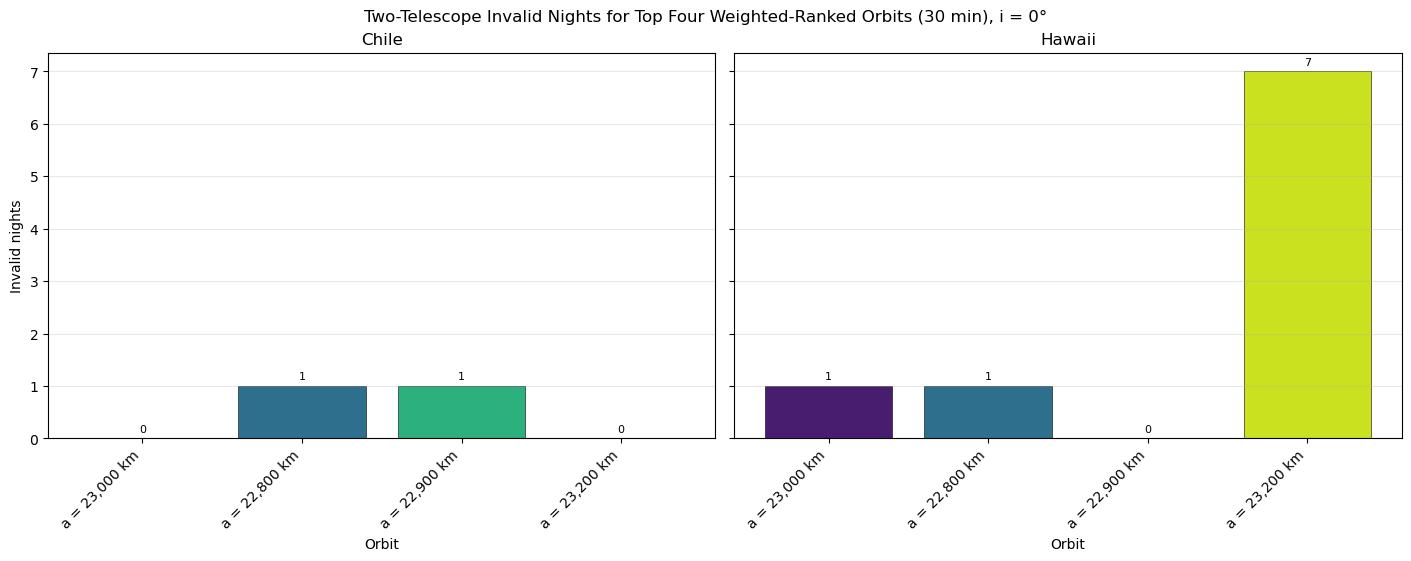

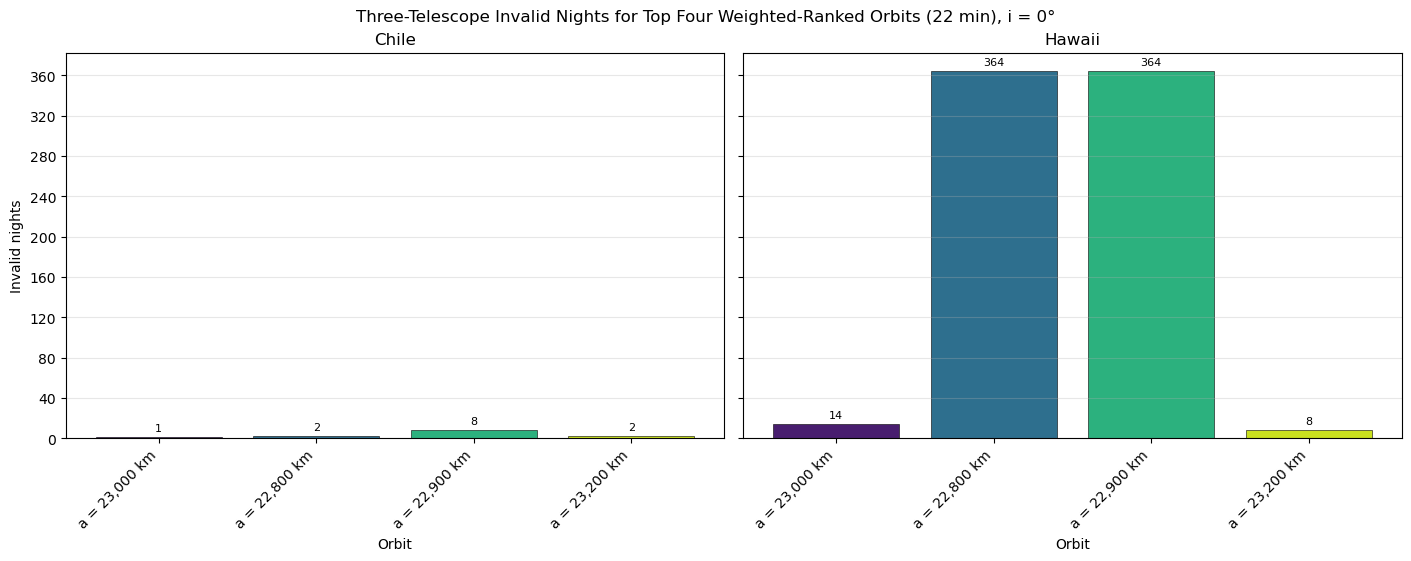

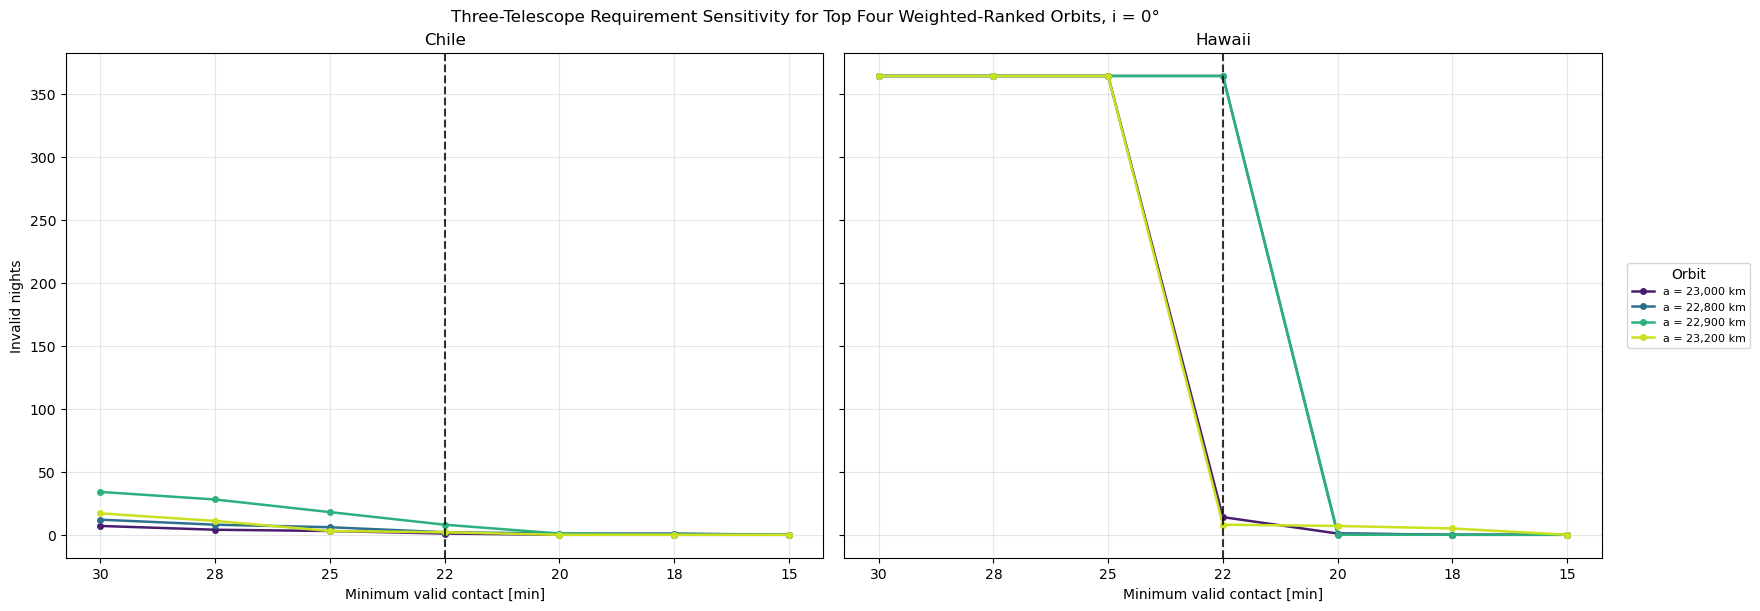

In [11]:

# Repeat all plots for the top four weighted-ranked orbits

# Number of top orbits to display in plots:
TOP_ORBIT_COUNT = 4

if len(weighted_overall_ranking) < TOP_ORBIT_COUNT:
    raise ValueError(f"At least {TOP_ORBIT_COUNT} orbits are required.")

top_orbit_order = weighted_overall_ranking.index[:TOP_ORBIT_COUNT].tolist()
top_cases = [next(case for case in CASES if case["name"] == orbit) for orbit in top_orbit_order]
top_orbit_labels = [orbit_label(case) for case in top_cases]
top_x = np.arange(TOP_ORBIT_COUNT)

print("Top four weighted-ranked orbits:")
display(
    weighted_overall_ranking.loc[
        top_orbit_order, ["Total weighted score", "Overall weighted rank"]]
    .round(2))


# Five-telescope invalid nights

fig, ax = plt.subplots(figsize=(10, 6))
top_invalid_night_totals = np.zeros(TOP_ORBIT_COUNT)

for telescope in VISIBILITY_TELESCOPES:
    telescope_data = (
        visibility_invalid_nights[visibility_invalid_nights["Telescope"] == telescope]
        .set_index("Orbit").reindex(top_orbit_order))
    values = telescope_data["Invalid nights"].to_numpy()
    ax.bar(
        top_x, values, bottom=top_invalid_night_totals,
        color=VISIBILITY_COLORS[telescope], edgecolor="black",
        linewidth=0.4, label=telescope)
    top_invalid_night_totals += values

for position, total in zip(top_x, top_invalid_night_totals):
    ax.text(
        position, total, f"{int(total)}",
        ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title(plot_title("Invalid Nights by Telescope for Top Four Weighted-Ranked Orbits"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Invalid nights")
ax.set_xticks(top_x)
ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
ax.margins(y=0.08)
fig.tight_layout()
save_figure(fig, "top_four_five_telescope_invalid_nights_by_orbit.png")
plt.show()


# Five-telescope total contact time

bar_width = 0.8 / len(VISIBILITY_TELESCOPES)
fig, ax = plt.subplots(figsize=(10, 6))

for telescope_index, telescope in enumerate(VISIBILITY_TELESCOPES):
    telescope_data = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(top_orbit_order))
    positions = top_x + (telescope_index - (len(VISIBILITY_TELESCOPES) - 1) / 2) * bar_width
    ax.bar(
        positions, telescope_data["Total contact [h]"],
        width=bar_width, color=VISIBILITY_COLORS[telescope],
        edgecolor="black", linewidth=0.4, label=telescope)

ax.set_title(plot_title("Total Contact Time for Top Four Weighted-Ranked Orbits"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Total contact [h]")
ax.set_xticks(top_x)
ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
fig.tight_layout()
save_figure(fig, "top_four_five_telescope_total_contact.png")
plt.show()


# Five-telescope valid contact requirement sensitivity

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
x_requirement = np.arange(len(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

for case in top_cases:
    orbit_data = (
        visibility_sensitivity[visibility_sensitivity["Orbit"] == case["name"]]
        .set_index("Minimum valid contact [min]")
        .reindex(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

    axes[0].plot(
        x_requirement, orbit_data["Total invalid nights"],
        marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))
    axes[1].plot(
        x_requirement, orbit_data["Total valid contact [h]"],
        marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))

axes[0].set_title("Invalid Nights vs Valid Contact Requirement")
axes[0].set_xlabel("Minimum valid contact [min]")
axes[0].set_ylabel("Total invalid nights")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

axes[1].set_title("Valid Contact Time vs Valid Contact Requirement")
axes[1].set_xlabel("Minimum valid contact [min]")
axes[1].set_ylabel("Total valid contact [h]")

for ax in axes:
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(VISIBILITY_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(
        VISIBILITY_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN),
        color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="Orbit",
    loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Five-Telescope Requirement Sensitivity for Top Four Weighted-Ranked Orbits"))
save_figure(fig, "top_four_five_telescope_valid_contact_requirement_sensitivity.png")
plt.show()


# Regional two- and three-telescope invalid nights

top_two_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"]
    == CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN]

top_three_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"]
    == CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN]


def plot_top_regional_invalid_nights(scheduling_data, value_column, title, filename):
    """Plot Chile and Hawaii invalid nights for the top four orbits."""
    fig, axes = plt.subplots(
        1, len(REGIONAL_TELESCOPES),
        figsize=(14, 5.5), sharey=True, constrained_layout=True)

    if len(REGIONAL_TELESCOPES) == 1:
        axes = [axes]

    case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, TOP_ORBIT_COUNT))

    for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
        region_data = (
            scheduling_data[scheduling_data["Region"] == region_name]
            .set_index("Orbit").reindex(top_orbit_order))
        values = region_data[value_column].to_numpy()
        bars = ax.bar(top_x, values, color=case_colors, edgecolor="black", linewidth=0.4)
        ax.bar_label(bars, labels=[f"{int(value)}" for value in values], padding=3, fontsize=8)
        ax.set_title(region_name)
        ax.set_xlabel("Orbit")
        ax.set_xticks(top_x)
        ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel("Invalid nights")
    fig.suptitle(plot_title(title))
    save_figure(fig, filename)
    plt.show()


plot_top_regional_invalid_nights(
    top_two_telescope_scheduling,
    "Two-telescope invalid nights",
    f"Two-Telescope Invalid Nights for Top Four Weighted-Ranked Orbits ({CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN} min)",
    "top_four_two_telescope_invalid_nights_by_orbit.png")

plot_top_regional_invalid_nights(
    top_three_telescope_scheduling,
    "Three-telescope invalid nights",
    f"Three-Telescope Invalid Nights for Top Four Weighted-Ranked Orbits ({CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN} min)",
    "top_four_three_telescope_invalid_nights_by_orbit.png")


# Three-telescope valid contact requirement sensitivity

fig, axes = plt.subplots(
    1, len(REGIONAL_TELESCOPES),
    figsize=(16, 6), sharey=True, constrained_layout=True)

if len(REGIONAL_TELESCOPES) == 1:
    axes = [axes]

x_requirement = np.arange(len(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, TOP_ORBIT_COUNT))

for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
    region_data = scheduling_sensitivity[
        scheduling_sensitivity["Region"] == region_name]

    for case, color in zip(top_cases, case_colors):
        orbit_data = (
            region_data[region_data["Orbit"] == case["name"]]
            .set_index("Minimum valid contact [min]")
            .reindex(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
        ax.plot(
            x_requirement, orbit_data["Three-telescope invalid nights"],
            marker="o", linewidth=1.8, markersize=4,
            color=color, label=orbit_label(case))

    ax.set_title(region_name)
    ax.set_xlabel("Minimum valid contact [min]")
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(SCHEDULING_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(
        SCHEDULING_CONTACT_REQUIREMENTS_MIN.index(CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN),
        color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Invalid nights")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="Orbit",
    loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Three-Telescope Requirement Sensitivity for Top Four Weighted-Ranked Orbits"))
save_figure(fig, "top_four_three_telescope_valid_contact_requirement_sensitivity.png")
plt.show()